- **定义**：节点的后续执行路径在 **运行时** 才确定，可以根据当前状态、输入数据或中间结果，动态决定要触发哪些下游任务或跳转到哪个下游节点。

- 特点：

  - 下游执行目标可以在运行时选择；
  - 下游任务数量可以在运行时决定；
  - 可以为同一个下游节点动态创建多个执行任务；
  - 适合实现 Map-Reduce 式动态扇出、多任务并行处理、运行时条件跳转等场景。

  需要注意的是，所谓“动态”通常不是指运行时临时创建新的节点定义。节点本身一般仍需要在图编译前注册。动态性主要体现在：**运行时决定触发哪些节点，以及为这些节点创建多少个执行任务**。

- 典型用法：

  - **`Send`**（动态扇出任务/数据）
  - **`Command(goto=...)`**（运行时跳转到下游节点）

⚡ 核心判断：

> **运行时决定后续执行目标或任务数量 → 动态分支**

### 1. 并行节点

{
    'poem': '## 
《布偶狗》\n\n棉絮的鼻尖轻触我手背，\n你总爱把毛绒尾巴卷成问号。\n孩子抱着你当枕头，\n奶香混着棉絮味，在午后发酵。\
n\n左耳纽扣松了三次，\n妈妈缝回时总嘟囔“该换新的”。\n可你依然用脱线的嘴巴，\n接住我所有摔碎的果酱面包。\n\n暴雨夜雷
声炸响，\n你被塞进我被窝当盾牌。\n潮湿的绒毛贴着下巴，\n比任何咒语都更快驱散噩梦。\n\n如今你瘫在储物箱底，\n棉花从
裂缝里探出灰白的头。\n小主人已学会用钥匙开门，\n却再没有谁需要你彻夜守卫。\n\n但昨夜我看见月光爬上箱沿，\n你突然抖
落满身灰尘站起来，\n用纽扣眼睛对我眨了三下，\n像小时候偷吃糖果时那样。',
    'ci_poem': 
'《临江仙·布偶狗》\n彩线巧缝憨态，绒身软卧玲珑。\n琉璃眼儿映帘栊。\n尾摇春昼暖，耳垂晚霞红。\n\n长伴绣衾书案，时偎
玉指香浓。\n无言也解笑啼容。\n窗边守月缺，枕畔听风慵。\n\n注：我的创作思路是抓住布偶狗作为工艺品的特质，通过“彩线”“
绒身”“琉璃眼”等意象展现其精巧形态。下阕以拟人手法赋予其陪伴属性，“守月缺”“听风慵”等句既写实又传神，暗合主人怜爱之情
。全词兼顾物性描写与情感寄托，在古典词牌框架中注入现代生活气息。',
    'joke': '## 
布偶狗的笑话\n\n老王去宠物店买狗，店员热情推荐：“这是最新品种，布偶狗，不掉毛、不拆家、性格温顺，跟布偶猫一样好养！
”\n\n老王心动，花大价钱买回家。果然，这狗整天安安静静趴在沙发上，怎么撸都不动，眼睛圆溜溜地盯着人看。\n\n一周后老王
怒气冲冲找上门：“你们这狗是假的吧？我拿逗猫棒逗它，它就看一眼；拿球扔它，它翻个白眼继续趴着；喊它名字，它连耳朵都不
带抖一下的！”\n\n店员淡定回答：“先生，您可能误会了。我们这布偶狗，品种特点是——**你得先把它肚子里那根反着装的棍子抽
出来，它才会动。**”\n\n老王一愣：“什么棍子？”\n\n店员掰开狗肚子上的魔术贴，从里面抽出一根毛茸茸的、带绒布的棍子：“
喏，这是它‘灵魂’。不抽出来，它就是块狗形靠垫；抽出来往地上一戳——你看——”\n\n话音刚落，布偶狗“啪”地站起来，开始原地转
圈摇尾巴，尾巴还是布缝的，甩起来“啪啪”抽自己后脑勺。\n\n老王沉默三秒：“……那这棍子平时谁保管？”\n\n店员微笑：“当然是
你自己。温馨提示——**千万别让你家猫看见这根棍子，不然它叼走当逗猫棒，你家狗就永远是个坐垫了。**”'
}

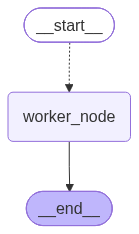

In [1]:
from collections.abc import Sequence
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send
from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek
from typing import TypedDict, Literal
from dotenv import load_dotenv
from IPython.display import display
from rich import print as rprint

load_dotenv(override=True)

CONTENT_TYPES = ["poem", "ci_poem", "joke"]

deepseek_model = ChatDeepSeek(
    model="deepseek-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(TypedDict):
    topic: str
    poem: str
    ci_poem: str
    joke: str

class WokerState(TypedDict):
    """
    私有状态，只对worker节点可用
    """
    content_type: Literal["poem", "ci_poem", "joke"]
    prompt: str

class InputState(TypedDict):
    topic: str

class OutputState(TypedDict):
    poem: str
    ci_poem: str
    joke: str

def worker_node(state: WokerState) -> OutputState:
    content_type = state["content_type"]
    prompt = state["prompt"]

    content = deepseek_model.invoke([HumanMessage(prompt)]).content
    return {
        content_type: content
    }

def router(state: InputState) -> Sequence[Send]:
    prompt = "请生成关于{}的{}"
    english2chinese = {
        "poem": "一首诗",
        "ci_poem": "一首词",
        "joke": "一个笑话"
    }
    topic = state["topic"]
    return [Send(
            "worker_node",
            {
                "content_type": content_type,
                "prompt": prompt.format(topic, english2chinese[content_type]),
            }
        ) for content_type in CONTENT_TYPES
    ]

builder = StateGraph(
    state_schema=OverAllState,
    input_schema=InputState,
    output_schema=OutputState,
)

builder.add_node("worker_node", worker_node)
builder.add_conditional_edges(
    START,
    router,
    path_map=["worker_node"],
)
builder.add_edge("worker_node", END)

graph = builder.compile()
res = graph.invoke({"topic": "布偶狗"})
rprint(res)

display(graph)

### 2. 条件分支
**`Command`** 是 **`LangGraph`** 中用于控制图执行的多功能原语，它的构造器可以接受四个参数，并记录在同名类属性中：

- **`update`**：更新图状态，效果等同于节点直接返回状态更新字典；
- **`goto`**：指定节点执行完成后的跳转目标，可用于运行时条件分支。当需要同时更新状态并控制跳转时，比单独使用条件边更合适；
- **`graph`**：存在子图时，用于指定跳转发生在哪一层图中，例如从子图跳转到父图；
- **`resume`**：用于恢复被中断的图执行，常见于 **`human-in-the-loop`** 场景。

可以通过 **`Command(goto=...)`** 在节点内部实现条件分支。与 **`add_conditional_edges()`** 相比，**`Command`** 更适合“状态更新”和“控制流跳转”需要放在同一个节点返回值中的场景。

============================== -> poem <- ==============================
{'topic': '布偶猫', 'content_type': 'poem', 'poem': '《咏布偶猫》\n蓝瞳玉貌雪绒身，步落无声性温存。\n芳丛戏蝶归深院，斜倚芸窗伴晓昏。\n\n注：我的诗以布偶猫为题材，通过“蓝瞳玉貌雪绒身”展现其外貌特征，以“步落无声性温存”传神地描绘其优雅温顺的性情。后两句通过戏蝶芳丛与倚窗伴晓昏的对比，既写出猫咪的活泼天性，又暗喻其作为伴侣动物的温情，整体虚实相生，动静结合，传递出对布偶猫的喜爱之情。'}
============================== -> joke <- ==============================
{'topic': '布偶猫', 'content_type': 'joke', 'joke': '一只布偶猫走进酒吧，对吧台后面的酒保说：“给我来一杯牛奶。”\n\n酒保说：“对不起，我们这儿不卖牛奶。”\n\n布偶猫说：“那给我来一杯温水也行。”\n\n酒保说：“也没有。”\n\n布偶猫想了想，说：“那……给我来一杯你的血。”\n\n酒保吓了一跳：“为什么？！”\n\n布偶猫说：“因为我是布偶猫啊，布偶（不）喝牛奶，布偶（不）喝温水，布偶（不）吸血……等等。”\n\n酒保：“……你到底要喝什么？”\n\n布偶猫：“算了，给我来杯自来水吧。”\n\n酒保：“好的。”\n\n布偶猫喝了一口，说：“嗯，果然，布偶（不）挑。”\n\n酒保：“……你走。”'}
============================== -> illegal <- ==============================
{'topic': '布偶猫', 'content_type': 'illegal'}


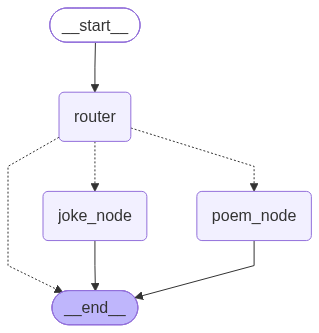

In [3]:
from langgraph.graph import StateGraph, START, END
from langgraph.types import Command
from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek
from typing import TypedDict, Literal
from dotenv import load_dotenv
from IPython.display import display
from rich import print as rprint

load_dotenv(override=True)

deepseek_model = ChatDeepSeek(
    model="deepseek-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(TypedDict):
    topic: str
    content_type: Literal["poem", "joke"]
    poem: str
    joke: str

def router(state: OverAllState) -> Command[Literal["poem_node", "joke_node", END]]:
    content_type = state["content_type"]
    if content_type == "poem":
        return Command(
            goto="poem_node",
        )
    elif content_type == "joke":
        return Command(
            goto="joke_node",
        )
    return Command(
        goto=END,
    )

def poem_node(state: OverAllState) -> OverAllState:
    topic = state["topic"]
    prompt = f"请生成一首关于{topic}的七言绝句"
    poem = deepseek_model.invoke([HumanMessage(prompt)]).content
    return {
        "poem": poem
    }

def joke_node(state: OverAllState) -> OverAllState:
    topic = state["topic"]
    prompt = f"请生成一个关于{topic}的冷笑话"
    joke = deepseek_model.invoke([HumanMessage(prompt)]).content
    return {
        "joke": joke
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("router", router)
builder.add_node("poem_node", poem_node)
builder.add_node("joke_node", joke_node)

builder.add_edge(START, "router")
builder.add_edge("poem_node",END)
builder.add_edge("joke_node",END)

graph = builder.compile()
poem_res = graph.invoke({"topic": "布偶猫", "content_type": "poem"})
joke_res = graph.invoke({"topic": "布偶猫", "content_type": "joke"})

# 这里故意传入一个不符合 Literal["poem", "joke"] 的值，
# 用来观察运行时兜底分支。
# 注意：Literal 主要服务于静态类型检查，
# 默认不会在 Python 运行时阻止非法值传入。
illegal_res = graph.invoke({
    "topic": "布偶猫",
    "content_type": "illegal"
})

print('=' * 30, '-> poem <-', '=' * 30)
print(poem_res)
print('=' * 30, '-> joke <-', '=' * 30)
print(joke_res)
print('=' * 30, '-> illegal <-', '=' * 30)
print(illegal_res)

display(graph)